In [1]:
!pip -q install kaggle mne eeglabio tensorflow scikit-learn pandas numpy scipy matplotlib seaborn

In [2]:
# CELL 1 — Windows path + Kaggle setup
import os
import shutil
from pathlib import Path

HOME = Path.home()   # usually C:\Users\U
DESKTOP = HOME / "Desktop"
WORK_ROOT = DESKTOP / "Shoili"

# Put your kaggle json here:
KAGGLE_JSON_SOURCE = WORK_ROOT / "kaggle (2).json"

# Kaggle expects this target:
KAGGLE_DIR = HOME / ".kaggle"
KAGGLE_JSON_TARGET = KAGGLE_DIR / "kaggle.json"

# All new folders/files will stay inside Desktop\Shoili
DOWNLOAD_BASE = WORK_ROOT / "openneuro_work"
ZIP_PATH = DOWNLOAD_BASE / "openneuro-ds004504.zip"
EXTRACT_DIR = DOWNLOAD_BASE / "openneuro_ds004504"
DATASET_ROOT = EXTRACT_DIR / "ds004504"
OUTPUT_ROOT = WORK_ROOT / "eeg_ad_hc_rebuild"

KAGGLE_DIR.mkdir(parents=True, exist_ok=True)
DOWNLOAD_BASE.mkdir(parents=True, exist_ok=True)
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

if not KAGGLE_JSON_SOURCE.exists():
    raise FileNotFoundError(f"Kaggle JSON file not found: {KAGGLE_JSON_SOURCE}")

shutil.copy2(KAGGLE_JSON_SOURCE, KAGGLE_JSON_TARGET)

# Windows permission-friendly
try:
    os.chmod(KAGGLE_JSON_TARGET, 0o600)
except Exception:
    pass

print("kaggle.json configured at:", KAGGLE_JSON_TARGET)
print("Download folder:", DOWNLOAD_BASE)
print("Dataset root will be:", DATASET_ROOT)
print("Output root:", OUTPUT_ROOT)


kaggle.json configured at: C:\Users\U\.kaggle\kaggle.json
Download folder: C:\Users\U\Desktop\Shoili\openneuro_work
Dataset root will be: C:\Users\U\Desktop\Shoili\openneuro_work\openneuro_ds004504\ds004504
Output root: C:\Users\U\Desktop\Shoili\eeg_ad_hc_rebuild


In [3]:
# CELL 2 — Imports + config + GPU check
import os
import gc
import json
import time
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mne
import tensorflow as tf

from sklearn.model_selection import StratifiedKFold, StratifiedShuffleSplit
from sklearn.metrics import (
    confusion_matrix, f1_score, accuracy_score, roc_auc_score, roc_curve
)
from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras import Model, layers, utils
from tensorflow.keras.callbacks import (
    CSVLogger, TerminateOnNaN, ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
)
from tensorflow.keras.constraints import max_norm

from IPython.display import display

warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
tf.get_logger().setLevel("ERROR")
mne.set_log_level("ERROR")

SEED = 42

def set_all_seeds(seed=42):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

set_all_seeds(SEED)

# GPU memory growth — prevents TF from allocating all VRAM at once
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("GPU memory growth enabled.")
    except RuntimeError as e:
        print("Could not set memory growth:", e)
else:
    print("No GPU detected by TensorFlow.")

# Mixed precision — ~2x speedup on modern GPUs (Volta / Ampere and newer)
from tensorflow.keras import mixed_precision
mixed_precision.set_global_policy("mixed_float16")
print("Mixed precision policy:", mixed_precision.global_policy().name)

CONFIG = {
    "dataset_root": DATASET_ROOT,
    "output_root": OUTPUT_ROOT,

    "analysis_channels": [
        "Fp1","Fp2","F7","F3","Fz","F4","F8",
        "T3","C3","Cz","C4","T4",
        "T5","P3","Pz","P4","T6","O1","O2"
    ],

    "target_sfreq": 256,
    "window_sec": 30,
    "overlap_sec": 15,   # 50 % overlap
    "step_sec": 15,      # step = window - overlap

    "task_name": "AD_vs_HC",
    "normalization": "channel_segment_zscore",

    "epochs": 20,
    "batch_size": 8,     # kept small — overlap doubles segment count vs 25s
    "learning_rate": 3e-4,
    "weight_decay": 1e-4,
    "label_smoothing": 0.0,

    "n_splits": 10,
    "val_ratio": 0.10,

    "resume_training": True,
}

CONFIG["output_root"].mkdir(parents=True, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("MNE:", mne.__version__)
print("Dataset root:", CONFIG["dataset_root"])
print("Output root:", CONFIG["output_root"])
print("GPUs found:", tf.config.list_physical_devices("GPU"))
print(f"Window: {CONFIG['window_sec']}s | Step: {CONFIG['step_sec']}s | Overlap: {CONFIG['overlap_sec']}s")


GPU memory growth enabled.
Mixed precision policy: mixed_float16
TensorFlow: 2.10.0
MNE: 1.11.0
Dataset root: C:\Users\U\Desktop\Shoili\openneuro_work\openneuro_ds004504\ds004504
Output root: C:\Users\U\Desktop\Shoili\eeg_ad_hc_rebuild
GPUs found: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Window: 30s | Step: 15s | Overlap: 15s


In [4]:
# CELL 3 — Download + extract dataset (safe to rerun)
import os
import zipfile
import subprocess

if DATASET_ROOT.exists():
    print("Dataset already extracted at:", DATASET_ROOT)
else:
    if not ZIP_PATH.exists():
        print("Downloading dataset zip from Kaggle...")
        cmd = ["kaggle", "datasets", "download", "-d", "thngdngvn/openneuro-ds004504", "-p", str(DOWNLOAD_BASE)]
        result = subprocess.run(cmd, capture_output=True, text=True)
        print(result.stdout)
        if result.returncode != 0:
            print(result.stderr)
            raise RuntimeError("Kaggle download failed.")
    else:
        print("Zip already exists:", ZIP_PATH)

    print("Extracting zip...")
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(EXTRACT_DIR)

    print("Extraction complete:", EXTRACT_DIR)

print("Exists participants.tsv:", (DATASET_ROOT / "participants.tsv").exists())
print("Sample top-level items:", sorted([p.name for p in DATASET_ROOT.iterdir()])[:20] if DATASET_ROOT.exists() else "dataset not found")


Dataset already extracted at: C:\Users\U\Desktop\Shoili\openneuro_work\openneuro_ds004504\ds004504
Exists participants.tsv: True
Sample top-level items: ['derivatives', 'participants.tsv']


In [5]:
import os
import gc
import json
import time
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mne
import tensorflow as tf

from sklearn.model_selection import StratifiedKFold, StratifiedShuffleSplit
from sklearn.metrics import (
    confusion_matrix, f1_score, accuracy_score, roc_auc_score, roc_curve
)
from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras import Model, layers, utils
from tensorflow.keras.callbacks import (
    CSVLogger, TerminateOnNaN, ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
)
from tensorflow.keras.constraints import max_norm

from IPython.display import display

warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
tf.get_logger().setLevel("ERROR")
mne.set_log_level("ERROR")

SEED = 42

def set_all_seeds(seed=42):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

set_all_seeds(SEED)

# GPU memory growth
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("GPU memory growth enabled.")
    except RuntimeError as e:
        print("Could not set memory growth:", e)
else:
    print("No GPU detected by TensorFlow.")

# Mixed precision
from tensorflow.keras import mixed_precision
mixed_precision.set_global_policy("mixed_float16")
print("Mixed precision policy:", mixed_precision.global_policy().name)

CONFIG = {
    "dataset_root": DATASET_ROOT,
    "output_root": OUTPUT_ROOT,

    "analysis_channels": [
        "Fp1","Fp2","F7","F3","Fz","F4","F8",
        "T3","C3","Cz","C4","T4",
        "T5","P3","Pz","P4","T6","O1","O2"
    ],

    "target_sfreq": 256,
    "window_sec": 30,
    "overlap_sec": 15,
    "step_sec": 15,

    "task_name": "AD_vs_HC",
    "normalization": "channel_segment_zscore",

    "epochs": 20,
    "batch_size": 8,
    "learning_rate": 3e-4,
    "weight_decay": 1e-4,
    "label_smoothing": 0.0,

    "n_splits": 10,
    "val_ratio": 0.10,

    "resume_training": True,
}

CONFIG["output_root"].mkdir(parents=True, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("MNE:", mne.__version__)
print("Dataset root:", CONFIG["dataset_root"])
print("Output root:", CONFIG["output_root"])
print("GPU:", tf.config.list_physical_devices("GPU"))
print(f"Window: {CONFIG['window_sec']}s | Step: {CONFIG['step_sec']}s | Overlap: {CONFIG['overlap_sec']}s")


GPU memory growth enabled.
Mixed precision policy: mixed_float16
TensorFlow: 2.10.0
MNE: 1.11.0
Dataset root: C:\Users\U\Desktop\Shoili\openneuro_work\openneuro_ds004504\ds004504
Output root: C:\Users\U\Desktop\Shoili\eeg_ad_hc_rebuild
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Window: 30s | Step: 15s | Overlap: 15s


In [6]:
PARTICIPANTS_TSV = CONFIG["dataset_root"] / "participants.tsv"
DERIVATIVES_ROOT = CONFIG["dataset_root"] / "derivatives"

GROUP_MAP = {
    "A": "AD", "AD": "AD", "ALZHEIMER": "AD", "ALZHEIMERS": "AD",
    "C": "CN", "CN": "CN", "HC": "CN", "CONTROL": "CN",
    "HEALTHY": "CN", "COGNITIVELY NORMAL": "CN",
    "F": "FTD", "FTD": "FTD", "FRONTOTEMPORAL DEMENTIA": "FTD",
}

CHANNEL_ALIAS = {
    "FP1":"Fp1","FP2":"Fp2","F7":"F7","F3":"F3","FZ":"Fz","F4":"F4","F8":"F8",
    "T3":"T3","T7":"T3","C3":"C3","CZ":"Cz","C4":"C4","T4":"T4","T8":"T4",
    "T5":"T5","P7":"T5","P3":"P3","PZ":"Pz","P4":"P4","T6":"T6","P8":"T6",
    "O1":"O1","O2":"O2",
}

EXPECTED_COUNTS = {"AD": 36, "CN": 29, "FTD": 23}

def normalize_group(x):
    x = str(x).strip().upper().replace("_", " ").replace("-", " ")
    x = " ".join(x.split())
    if x in GROUP_MAP:
        return GROUP_MAP[x]
    raise ValueError(f"Unknown group label: {x}")

def load_participants():
    df = pd.read_csv(PARTICIPANTS_TSV, sep="\t")
    df["participant_id"] = df["participant_id"].astype(str).str.strip()

    group_col = next(
        (c for c in df.columns if c.lower() in {"group", "diagnosis", "label"}),
        None
    )
    if group_col is None:
        raise RuntimeError(f"No group/diagnosis column found. Columns: {list(df.columns)}")

    df["group"] = df[group_col].apply(normalize_group)
    return df[["participant_id", "group"]].copy()

def canon_ch(ch):
    return CHANNEL_ALIAS.get(str(ch).strip().upper().replace(" ", ""), ch)

def canonicalize_channels(raw):
    renames = {ch: canon_ch(ch) for ch in raw.ch_names if canon_ch(ch) != ch}
    if renames:
        raw.rename_channels(renames)
    return raw

def find_derivative_set(sub_id: str) -> Path:
    eeg_dir = DERIVATIVES_ROOT / sub_id / "eeg"
    preferred = eeg_dir / f"{sub_id}_task-eyesclosed_eeg.set"
    if preferred.exists():
        return preferred
    hits = sorted(eeg_dir.glob("*task-eyesclosed*_eeg.set"))
    if hits:
        return hits[0]
    raise FileNotFoundError(f"No derivative .set file found for {sub_id} in {eeg_dir}")

participants_all_df = load_participants()
counts_all = participants_all_df["group"].value_counts().to_dict()
for grp, exp in EXPECTED_COUNTS.items():
    got = int(counts_all.get(grp, 0))
    assert got == exp, f"Count mismatch for {grp}: expected {exp}, got {got}"

# Strictly AD and CN only — FTD excluded
participants_df = participants_all_df[
    participants_all_df["group"].isin(["AD", "CN"])
].copy().reset_index(drop=True)

sub_to_group = dict(zip(participants_df["participant_id"], participants_df["group"]))

print("Participants loaded.")
print("All counts:", counts_all)
print("AD/CN only:", participants_df["group"].value_counts().to_dict())
display(participants_df.head())


Participants loaded.
All counts: {'AD': 36, 'CN': 29, 'FTD': 23}
AD/CN only: {'AD': 36, 'CN': 29}


,participant_id,group
0,sub-001,AD
1,sub-002,AD
2,sub-003,AD
3,sub-004,AD
4,sub-005,AD


In [7]:
def load_and_prepare_raw(sub_id: str):
    """
    Returns:
        data_uv: (19, n_samples) float32 in microvolts
    """
    path = find_derivative_set(sub_id)

    raw = mne.io.read_raw_eeglab(str(path), preload=True, verbose=False)
    raw = canonicalize_channels(raw)

    missing = [ch for ch in CONFIG["analysis_channels"] if ch not in raw.ch_names]
    if missing:
        raise RuntimeError(f"{sub_id}: missing channels after canonicalization: {missing}")

    raw = raw.copy().pick(CONFIG["analysis_channels"])
    raw.reorder_channels(CONFIG["analysis_channels"])

    if int(round(raw.info["sfreq"])) != CONFIG["target_sfreq"]:
        raw.resample(CONFIG["target_sfreq"], verbose=False)

    data_uv = (raw.get_data() * 1e6).astype(np.float32)

    del raw
    gc.collect()
    return data_uv

# quick sanity check
sample_ids = participants_df["participant_id"].head(2).tolist()
for sid in sample_ids:
    x = load_and_prepare_raw(sid)
    print(sid, x.shape, f"duration_sec={x.shape[1]/CONFIG['target_sfreq']:.1f}")
    del x
    gc.collect()


sub-001 (19, 153549) duration_sec=599.8
sub-002 (19, 203034) duration_sec=793.1


In [8]:
# ── Segmentation config ───────────────────────────────────────────────────────
CONFIG["window_sec"]  = 30
CONFIG["overlap_sec"] = 15
CONFIG["step_sec"]    = 15   # stride = window - overlap  =>  50% overlap

SEG_ROOT = CONFIG["output_root"] / "segments_30s_15s_overlap_ad_cn"
META_ROOT = CONFIG["output_root"] / "metadata"
META_ROOT.mkdir(parents=True, exist_ok=True)

META_CSV          = META_ROOT / "segment_metadata_30s_15s_overlap.csv"
SUBJECT_AUDIT_CSV = META_ROOT / "subject_audit_30s_15s_overlap.csv"


# ── Overlapping segmentation function ────────────────────────────────────────
def segment_overlap(data_uv: np.ndarray, sfreq: int, win_sec: int, step_sec: int):
    """
    Sliding-window segmentation with overlap.

    Args:
        data_uv  : (n_channels, n_samples) float32
        sfreq    : sampling frequency in Hz
        win_sec  : window length in seconds  (e.g. 30)
        step_sec : stride in seconds         (e.g. 15 => 50% overlap)

    Returns:
        segments : (n_segments, n_channels, window_samples) float32
    """
    win_samples  = int(win_sec  * sfreq)
    step_samples = int(step_sec * sfreq)
    total_samples = data_uv.shape[1]

    starts = list(range(0, total_samples - win_samples + 1, step_samples))

    if len(starts) == 0:
        return np.empty((0, data_uv.shape[0], win_samples), dtype=np.float32)

    return np.stack(
        [data_uv[:, s : s + win_samples] for s in starts],
        axis=0
    ).astype(np.float32)

# ── Build segments ────────────────────────────────────────────────────────────
def build_30s_15s_overlap_segments(force_rebuild=False):
    if force_rebuild and SEG_ROOT.exists():
        shutil.rmtree(SEG_ROOT)

    SEG_ROOT.mkdir(parents=True, exist_ok=True)

    rows = []
    subject_rows = []

    for sub_id in sorted(participants_df["participant_id"].tolist()):
        group = sub_to_group[sub_id]

        # ── strict AD/CN guard (no FTD) ──────────────────────────────────────
        if group not in ("AD", "CN"):
            print(f"  Skipping {sub_id} (group={group})")
            continue

        data_uv = load_and_prepare_raw(sub_id)

        subject_rows.append({
            "subject_id": sub_id,
            "group": group,
            "n_channels": data_uv.shape[0],
            "n_samples": data_uv.shape[1],
            "duration_sec": round(data_uv.shape[1] / CONFIG["target_sfreq"], 2),
        })

        segs = segment_overlap(
            data_uv,
            CONFIG["target_sfreq"],
            CONFIG["window_sec"],
            CONFIG["step_sec"],
        )

        out_dir = SEG_ROOT / group
        out_dir.mkdir(parents=True, exist_ok=True)

        expected_shape = segs[0].shape if len(segs) > 0 else None

        for i, seg in enumerate(segs):
            fpath = out_dir / f"{sub_id}_seg_{i:04d}.npy"

            needs_save = force_rebuild or (not fpath.exists())
            if not needs_save and expected_shape is not None:
                existing = np.load(fpath, mmap_mode="r")
                if existing.shape != expected_shape:
                    needs_save = True   # stale file with wrong shape — overwrite
                del existing
                gc.collect()           # release mmap handle (required on Windows)

            if needs_save:
                np.save(fpath, seg)

            rows.append({
                "subject_id": sub_id,
                "group": group,
                "window": "30s+15s overlap",
                "filepath": str(fpath),
            })

        del data_uv, segs
        gc.collect()

    meta_df = (
        pd.DataFrame(rows)
        .sort_values(["group", "subject_id", "filepath"])
        .reset_index(drop=True)
    )

    subject_df = (
        pd.DataFrame(subject_rows)
        .sort_values(["group", "subject_id"])
        .reset_index(drop=True)
    )

    meta_df.to_csv(META_CSV, index=False)
    subject_df.to_csv(SUBJECT_AUDIT_CSV, index=False)

    return meta_df, subject_df

meta_df, subject_audit_df = build_30s_15s_overlap_segments(force_rebuild=False)

count_df = (
    meta_df.groupby("group")
    .size()
    .rename("generated_count")
    .reset_index()
)

print("Generated 30s+15s overlap counts:")
display(count_df)


# ── Paper reference counts (optional comparison) ─────────────────────────────
PAPER_COUNTS_30S_15S = {"CN": 1563, "AD": 1888}

print("\nComparison with paper counts:")
for grp in ["CN", "AD"]:
    generated = int(count_df.loc[count_df["group"] == grp, "generated_count"].values[0])
    paper_val = PAPER_COUNTS_30S_15S[grp]

    diff = generated - paper_val

    print(f"{grp}: Generated = {generated} | Paper = {paper_val} | Diff = {diff}")


# ── Validation assertions ─────────────────────────────────────────────────────
assert set(count_df["group"].tolist()) == {"AD", "CN"}, \
    f"Unexpected groups in metadata: {set(count_df['group'].tolist())}"

assert count_df["generated_count"].gt(0).all(), \
    "One or more groups have zero segments!"

assert (meta_df["window"] == "30s+15s overlap").all(), \
    "Window label mismatch in metadata!"

# Shape sanity check
sample_path = Path(meta_df.iloc[0]["filepath"])
sample_seg  = np.load(sample_path)
expected_len = CONFIG["window_sec"] * CONFIG["target_sfreq"]   # 30 * 256 = 7680
print(f"Sample segment shape: {sample_seg.shape}  (expected time axis = {expected_len})")
assert sample_seg.shape[1] == expected_len, \
    f"Wrong segment length: expected {expected_len}, got {sample_seg.shape[1]}"

print("All validation assertions passed.")
print("Saved:")
print(META_CSV)
print(SUBJECT_AUDIT_CSV)


Generated 30s+15s overlap counts:


,group,generated_count
0,AD,1888
1,CN,1563



Comparison with paper counts:
CN: Generated = 1563 | Paper = 1563 | Diff = 0
AD: Generated = 1888 | Paper = 1888 | Diff = 0
Sample segment shape: (19, 7680)  (expected time axis = 7680)
All validation assertions passed.
Saved:
C:\Users\U\Desktop\Shoili\eeg_ad_hc_rebuild\metadata\segment_metadata_30s_15s_overlap.csv
C:\Users\U\Desktop\Shoili\eeg_ad_hc_rebuild\metadata\subject_audit_30s_15s_overlap.csv


In [9]:
def cleanup_memory():
    tf.keras.backend.clear_session()
    gc.collect()

def normalize_seg_channelwise(seg_ch_time: np.ndarray):
    seg = seg_ch_time.astype(np.float32, copy=False)
    mu = seg.mean(axis=1, keepdims=True)
    sd = seg.std(axis=1, keepdims=True)
    sd[sd < 1e-6] = 1.0
    return (seg - mu) / sd

def load_subset_arrays(subset_df: pd.DataFrame):
    """
    Returns:
      X: (N, time, ch, 1)
      y: (N,)
      subjects: (N,)
    """
    subset_df = subset_df.reset_index(drop=True)
    first = np.load(subset_df.iloc[0]["filepath"], mmap_mode="r")

    if first.ndim != 2:
        raise ValueError(f"Expected 2D segment array, got {first.shape}")

    # stored shape is (channels, time)
    n_ch, time_len = first.shape

    X = np.empty((len(subset_df), time_len, n_ch, 1), dtype=np.float32)
    y = subset_df["y"].to_numpy(np.int64)
    subjects = subset_df["subject_id"].astype(str).to_numpy()

    for i, row in enumerate(subset_df.itertuples(index=False)):
        seg = np.load(row.filepath)
        seg = normalize_seg_channelwise(seg)  # (ch, time)
        seg = seg.T[..., None]                # (time, ch, 1)
        X[i] = seg

    return X, y, subjects

def compute_metrics_from_probs(y_true, disease_prob, threshold=0.5):
    y_true = np.asarray(y_true).astype(int)
    disease_prob = np.asarray(disease_prob).astype(np.float32)
    y_pred = (disease_prob >= threshold).astype(int)

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    sensitivity = 100.0 * tp / (tp + fn) if (tp + fn) > 0 else np.nan
    specificity = 100.0 * tn / (tn + fp) if (tn + fp) > 0 else np.nan
    precision   = 100.0 * tp / (tp + fp) if (tp + fp) > 0 else np.nan
    f1          = float(f1_score(y_true, y_pred, zero_division=0))
    accuracy    = 100.0 * accuracy_score(y_true, y_pred)

    try:
        roc_auc = float(roc_auc_score(y_true, disease_prob))
    except Exception:
        roc_auc = np.nan

    return {
        "sensitivity": sensitivity,
        "specificity": specificity,
        "precision": precision,
        "f1": f1,
        "accuracy": accuracy,
        "roc_auc": roc_auc,
        "TP": int(tp),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
    }

def find_best_threshold(y_true, disease_prob, metric="accuracy"):
    thresholds = np.linspace(0.05, 0.95, 181)
    best_thr = 0.5
    best_score = -np.inf
    best_metrics = None

    for thr in thresholds:
        m = compute_metrics_from_probs(y_true, disease_prob, threshold=thr)
        bal_acc = 0.5 * (m["sensitivity"] + m["specificity"])

        if metric == "accuracy":
            score = m["accuracy"]
        elif metric == "f1":
            score = m["f1"]
        elif metric == "balanced_accuracy":
            score = bal_acc
        else:
            raise ValueError(metric)

        if score > best_score:
            best_score = score
            best_thr = float(thr)
            best_metrics = dict(m)
            best_metrics["balanced_accuracy"] = float(bal_acc)

    return best_thr, best_metrics

def append_df_csv(df: pd.DataFrame, path: Path):
    header = not path.exists()
    df.to_csv(path, mode="a", index=False, header=header)

def save_json(obj, path: Path):
    with open(path, "w") as f:
        json.dump(obj, f, indent=2)

def make_callbacks(save_dir: Path, tag: str, patience_es=6, patience_lr=3):
    save_dir.mkdir(parents=True, exist_ok=True)
    return [
        TerminateOnNaN(),
        EarlyStopping(
            monitor="val_loss",
            patience=patience_es,
            restore_best_weights=True,
            verbose=1
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=patience_lr,
            min_lr=1e-5,
            verbose=1
        ),
        CSVLogger(str(save_dir / f"{tag}_history.csv"), append=False),
        ModelCheckpoint(
            filepath=str(save_dir / f"{tag}_best.weights.h5"),
            monitor="val_loss",
            save_best_only=True,
            save_weights_only=True,
            verbose=1
        ),
    ]


In [10]:
# CELL 9 — Phase-2 dual-branch model (time + frequency, SE blocks)

def se_block_2d(x, ratio=8, name_prefix="se"):
    channels = int(x.shape[-1])
    se = layers.GlobalAveragePooling2D(name=f"{name_prefix}_gap")(x)
    se = layers.Dense(max(channels // ratio, 8), activation="relu", name=f"{name_prefix}_fc1")(se)
    se = layers.Dense(channels, activation="sigmoid", name=f"{name_prefix}_fc2")(se)
    se = layers.Reshape((1, 1, channels), name=f"{name_prefix}_reshape")(se)
    return layers.Multiply(name=f"{name_prefix}_scale")([x, se])


def build_phase2_dual_branch_model_v2(input_shape,
                                      learning_rate=3e-4,
                                      label_smoothing=0.0,
                                      dropout_rate=0.35,
                                      weight_decay=1e-4):

    T, C, _ = input_shape
    sfreq = CONFIG["target_sfreq"]

    inp = layers.Input(shape=input_shape, name="eeg_input")

    # ================= TIME BRANCH =================
    t1 = layers.Conv2D(32, (32, 1), padding="same", use_bias=False)(inp)
    t1 = layers.BatchNormalization()(t1)
    t1 = layers.Activation("elu")(t1)

    t2 = layers.Conv2D(32, (64, 1), padding="same", use_bias=False)(inp)
    t2 = layers.BatchNormalization()(t2)
    t2 = layers.Activation("elu")(t2)

    t3 = layers.Conv2D(32, (128, 1), padding="same", use_bias=False)(inp)
    t3 = layers.BatchNormalization()(t3)
    t3 = layers.Activation("elu")(t3)

    t = layers.Concatenate(axis=-1)([t1, t2, t3])

    t = layers.DepthwiseConv2D(
        kernel_size=(1, C),
        depth_multiplier=2,
        padding="valid",
        use_bias=False,
        depthwise_constraint=max_norm(1.0)
    )(t)

    t = layers.BatchNormalization()(t)
    t = layers.Activation("elu")(t)

    # FIX 1: Added unique name_prefix
    t = se_block_2d(t, ratio=8, name_prefix="time_se1")

    t = layers.AveragePooling2D(pool_size=(4, 1))(t)
    t = layers.SpatialDropout2D(0.20)(t)

    t = layers.SeparableConv2D(192, (16, 1), padding="same", use_bias=False)(t)
    t = layers.BatchNormalization()(t)
    t = layers.Activation("elu")(t)

    t = layers.AveragePooling2D(pool_size=(4, 1))(t)
    t = layers.SpatialDropout2D(0.25)(t)

    t = layers.SeparableConv2D(256, (8, 1), padding="same", use_bias=False)(t)
    t = layers.BatchNormalization()(t)
    t = layers.Activation("elu")(t)

    # FIX 2: Added unique name_prefix
    t = se_block_2d(t, ratio=8, name_prefix="time_se2")

    t = layers.AveragePooling2D(pool_size=(2, 1))(t)
    t = layers.SpatialDropout2D(dropout_rate)(t)

    t_embed = layers.GlobalAveragePooling2D()(t)

    # ================= FREQUENCY BRANCH =================
    fx = layers.Lambda(lambda z: tf.squeeze(z, axis=-1))(inp)
    fx = layers.Lambda(lambda z: tf.transpose(z, perm=[0, 2, 1]))(fx)

    # CRITICAL FIX: cast inside rfft
    fx = layers.Lambda(
        lambda z: tf.signal.rfft(tf.cast(z, tf.float32))
    )(fx)

    fx = layers.Lambda(lambda z: tf.abs(z))(fx)

    max_bin = min((T // 2) + 1, int((45.0 * T) / sfreq) + 1)
    fx = layers.Lambda(lambda z: z[:, :, :max_bin])(fx)

    fx = layers.Lambda(lambda z: tf.math.log1p(z))(fx)

    fx = layers.Lambda(lambda z: tf.transpose(z, perm=[0, 2, 1]))(fx)
    fx = layers.Lambda(lambda z: tf.expand_dims(z, axis=-1))(fx)

    f = layers.Conv2D(48, (7, 3), padding="same", use_bias=False)(fx)
    f = layers.BatchNormalization()(f)
    f = layers.Activation("elu")(f)
    f = layers.MaxPooling2D(pool_size=(2, 1))(f)
    f = layers.Dropout(0.20)(f)

    f = layers.Conv2D(96, (5, 3), padding="same", use_bias=False)(f)
    f = layers.BatchNormalization()(f)
    f = layers.Activation("elu")(f)
    f = layers.MaxPooling2D(pool_size=(2, 1))(f)
    f = layers.Dropout(0.25)(f)

    f = layers.Conv2D(192, (3, 3), padding="same", use_bias=False)(f)
    f = layers.BatchNormalization()(f)
    f = layers.Activation("elu")(f)

    # FIX 3: Added unique name_prefix
    f = se_block_2d(f, ratio=8, name_prefix="freq_se1")

    f = layers.MaxPooling2D(pool_size=(2, 1))(f)
    f = layers.Dropout(dropout_rate)(f)

    f_embed = layers.GlobalAveragePooling2D()(f)

    # ================= FUSION =================
    z = layers.Concatenate()([t_embed, f_embed])

    z = layers.Dense(768, activation="relu")(z)
    z = layers.Dropout(0.45)(z)

    z = layers.Dense(192, activation="relu")(z)
    z = layers.Dropout(0.30)(z)

    out = layers.Dense(2, activation="softmax", dtype="float32")(z)

    model = Model(inp, out, name="phase2_dual_branch_time_freq_v2")

    optimizer = tf.keras.optimizers.Adam(
        learning_rate=learning_rate,
        clipnorm=1.0
    )

    model.compile(
        optimizer=optimizer,
        loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=label_smoothing),
        metrics=["accuracy"]
    )

    return model

In [11]:
RUN_NAME = "phase2_clean_30s_15s_overlap_paper10fold_batch8"
RUN_DIR = CONFIG["output_root"] / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)

FOLD_METRICS_CSV  = RUN_DIR / "fold_metrics.csv"
SEGMENT_PREDS_CSV = RUN_DIR / "segment_predictions.csv"

def make_json_safe(obj):
    if isinstance(obj, Path):
        return str(obj)
    if isinstance(obj, dict):
        return {str(k): make_json_safe(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [make_json_safe(v) for v in obj]
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, np.floating):
        return float(obj)
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    return obj

def save_json(obj, path: Path):
    with open(path, "w") as f:
        json.dump(make_json_safe(obj), f, indent=2)

# ── Load and filter metadata — strictly AD and CN only ────────────────────────
meta = pd.read_csv(META_CSV).copy()
meta = meta[
    (meta["window"] == "30s+15s overlap") &
    (meta["group"].isin(["CN", "AD"]))
].reset_index(drop=True)
meta["y"] = meta["group"].map({"CN": 0, "AD": 1}).astype(np.int64)
meta["subject_id"] = meta["subject_id"].astype(str)

print("Training rows:", len(meta))
print("Class counts:", meta["group"].value_counts().to_dict())

# Final FTD guard
assert "FTD" not in meta["group"].unique(), "FTD subjects found in training meta — check segmentation!"

if CONFIG["resume_training"] and FOLD_METRICS_CSV.exists():
    done_df = pd.read_csv(FOLD_METRICS_CSV)
    done_folds = set(done_df["fold"].astype(int).tolist())
    print("Resuming. Completed folds:", sorted(done_folds))
else:
    done_folds = set()
    if FOLD_METRICS_CSV.exists():
        FOLD_METRICS_CSV.unlink()
    if SEGMENT_PREDS_CSV.exists():
        SEGMENT_PREDS_CSV.unlink()

skf = StratifiedKFold(
    n_splits=CONFIG["n_splits"],
    shuffle=True,
    random_state=SEED
)

start_all = time.time()

for fold_idx, (trainval_idx, test_idx) in enumerate(skf.split(meta, meta["y"]), start=1):
    if fold_idx in done_folds:
        print(f"Skipping fold {fold_idx} (already completed)")
        continue

    print("\n" + "=" * 90)
    print(f"PHASE-2 CLEAN 30s+15s OVERLAP 10-FOLD | Fold {fold_idx}/{CONFIG['n_splits']}")
    print("=" * 90)

    fold_start = time.time()
    cleanup_memory()
    set_all_seeds(SEED + fold_idx)

    trainval_meta = meta.iloc[trainval_idx].reset_index(drop=True)
    test_meta     = meta.iloc[test_idx].reset_index(drop=True)

    sss = StratifiedShuffleSplit(
        n_splits=1,
        test_size=CONFIG["val_ratio"],
        random_state=SEED + fold_idx
    )
    tr_idx, val_idx = next(sss.split(trainval_meta, trainval_meta["y"]))

    train_meta = trainval_meta.iloc[tr_idx].reset_index(drop=True)
    val_meta   = trainval_meta.iloc[val_idx].reset_index(drop=True)

    print(f"train={len(train_meta)} | val={len(val_meta)} | test={len(test_meta)}")

    X_train, y_train, sub_train = load_subset_arrays(train_meta)
    X_val,   y_val,   sub_val   = load_subset_arrays(val_meta)
    X_test,  y_test,  sub_test  = load_subset_arrays(test_meta)

    print("X_train:", X_train.shape, "| X_val:", X_val.shape, "| X_test:", X_test.shape)

    class_weights_arr = compute_class_weight(
        class_weight="balanced",
        classes=np.array([0, 1]),
        y=y_train
    )
    class_weight = {0: float(class_weights_arr[0]), 1: float(class_weights_arr[1])}
    print("Class weights:", class_weight)

    model = build_phase2_dual_branch_model_v2(
        input_shape=X_train.shape[1:],
        learning_rate=CONFIG["learning_rate"],
        label_smoothing=CONFIG["label_smoothing"],
        dropout_rate=0.35,
        weight_decay=CONFIG["weight_decay"]
    )

    callbacks = make_callbacks(RUN_DIR, f"fold_{fold_idx:02d}")

    # tf.data pipeline — prefetch keeps GPU fed while CPU loads next batch
    y_train_cat = utils.to_categorical(y_train, num_classes=2)
    y_val_cat   = utils.to_categorical(y_val,   num_classes=2)

    train_ds = (
        tf.data.Dataset.from_tensor_slices((X_train, y_train_cat))
        .shuffle(len(X_train), seed=SEED + fold_idx)
        .batch(CONFIG["batch_size"])
        .prefetch(tf.data.AUTOTUNE)
    )
    val_ds = (
        tf.data.Dataset.from_tensor_slices((X_val, y_val_cat))
        .batch(CONFIG["batch_size"])
        .prefetch(tf.data.AUTOTUNE)
    )

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=CONFIG["epochs"],
        class_weight=class_weight,
        verbose=1,
        callbacks=callbacks,
    )

    val_ds_pred = (
        tf.data.Dataset.from_tensor_slices(X_val)
        .batch(CONFIG["batch_size"]).prefetch(tf.data.AUTOTUNE)
    )
    val_prob = model.predict(val_ds_pred, verbose=0)[:, 1]

    best_thr, best_val_metrics = find_best_threshold(
        y_true=y_val,
        disease_prob=val_prob,
        metric="accuracy"
    )

    test_ds_pred = (
        tf.data.Dataset.from_tensor_slices(X_test)
        .batch(CONFIG["batch_size"]).prefetch(tf.data.AUTOTUNE)
    )
    test_prob    = model.predict(test_ds_pred, verbose=0)[:, 1]
    test_default = compute_metrics_from_probs(y_test, test_prob, threshold=0.5)
    test_tuned   = compute_metrics_from_probs(y_test, test_prob, threshold=best_thr)

    fold_minutes = (time.time() - fold_start) / 60.0

    print(
        f"best_thr={best_thr:.4f} | "
        f"default_acc={test_default['accuracy']:.2f}% | "
        f"tuned_acc={test_tuned['accuracy']:.2f}% | "
        f"auc={test_default['roc_auc']:.4f} | "
        f"fold_time={fold_minutes:.2f} min"
    )

    fold_row = pd.DataFrame([{
        "fold": fold_idx,
        "best_threshold": best_thr,
        "fold_time_min": fold_minutes,

        "default_accuracy":    test_default["accuracy"],
        "default_sensitivity": test_default["sensitivity"],
        "default_specificity": test_default["specificity"],
        "default_precision":   test_default["precision"],
        "default_f1":          test_default["f1"],
        "default_roc_auc":     test_default["roc_auc"],

        "tuned_accuracy":    test_tuned["accuracy"],
        "tuned_sensitivity": test_tuned["sensitivity"],
        "tuned_specificity": test_tuned["specificity"],
        "tuned_precision":   test_tuned["precision"],
        "tuned_f1":          test_tuned["f1"],
        "tuned_roc_auc":     test_tuned["roc_auc"],

        "val_best_accuracy":    best_val_metrics["accuracy"],
        "val_best_sensitivity": best_val_metrics["sensitivity"],
        "val_best_specificity": best_val_metrics["specificity"],
        "val_best_precision":   best_val_metrics["precision"],
        "val_best_f1":          best_val_metrics["f1"],
        "val_best_roc_auc":     best_val_metrics["roc_auc"],
    }])
    append_df_csv(fold_row, FOLD_METRICS_CSV)

    seg_pred_df = pd.DataFrame({
        "fold": fold_idx,
        "subject_id": sub_test,
        "y_true": y_test.astype(int),
        "prob_disease": test_prob.astype(float),
        "pred_default_0_5": (test_prob >= 0.5).astype(int),
        "pred_tuned": (test_prob >= best_thr).astype(int),
        "threshold_used": float(best_thr),
    })
    append_df_csv(seg_pred_df, SEGMENT_PREDS_CSV)

    del X_train, y_train, sub_train, y_train_cat
    del X_val,   y_val,   sub_val,   y_val_cat
    del X_test,  y_test,  sub_test
    del val_prob, test_prob, history, model
    del seg_pred_df, fold_row, train_ds, val_ds, val_ds_pred, test_ds_pred
    cleanup_memory()

total_minutes = (time.time() - start_all) / 60.0
print(f"\nTotal elapsed time: {total_minutes:.2f} min")

fold_df = pd.read_csv(FOLD_METRICS_CSV)

summary_rows = []
for col in fold_df.columns:
    if col == "fold":
        continue
    vals = fold_df[col].astype(float)
    summary_rows.append({
        "metric": col,
        "mean":   float(vals.mean()),
        "std":    float(vals.std()),
        "min":    float(vals.min()),
        "max":    float(vals.max()),
    })

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(RUN_DIR / "summary.csv", index=False)

print("\nMain metrics (default threshold = 0.5):")
display(summary_df[summary_df["metric"].isin([
    "default_accuracy",
    "default_sensitivity",
    "default_specificity",
    "default_precision",
    "default_f1",
    "default_roc_auc",
    "fold_time_min",
])])

print("\nSecondary metrics (tuned threshold):")
display(summary_df[summary_df["metric"].isin([
    "tuned_accuracy",
    "tuned_sensitivity",
    "tuned_specificity",
    "tuned_precision",
    "tuned_f1",
    "tuned_roc_auc",
    "best_threshold",
])])

print("\nSaved files:")
print(FOLD_METRICS_CSV)
print(SEGMENT_PREDS_CSV)
print(RUN_DIR / "summary.csv")


Training rows: 3451
Class counts: {'AD': 1888, 'CN': 1563}

PHASE-2 CLEAN 30s+15s OVERLAP 10-FOLD | Fold 1/10
train=2794 | val=311 | test=346
X_train: (2794, 7680, 19, 1) | X_val: (311, 7680, 19, 1) | X_test: (346, 7680, 19, 1)
Class weights: {0: 1.1043478260869566, 1: 0.9136690647482014}
Epoch 1/20
350/350 [==============================] - ETA: 0s - loss: 0.4906 - accuracy: 0.7513
Epoch 1: val_loss improved from inf to 0.66286, saving model to C:\Users\U\Desktop\Shoili\eeg_ad_hc_rebuild\phase2_clean_30s_15s_overlap_paper10fold_batch8\fold_01_best.weights.h5
350/350 [==============================] - 106s 283ms/step - loss: 0.4906 - accuracy: 0.7513 - val_loss: 0.6629 - val_accuracy: 0.5884 - lr: 3.0000e-04
Epoch 2/20
350/350 [==============================] - ETA: 0s - loss: 0.3468 - accuracy: 0.8515
Epoch 2: val_loss improved from 0.66286 to 0.23390, saving model to C:\Users\U\Desktop\Shoili\eeg_ad_hc_rebuild\phase2_clean_30s_15s_overlap_paper10fold_batch8\fold_01_best.weights.h5
35

,metric,mean,std,min,max
1,fold_time_min,32.869148,0.172991,32.598805,33.223089
2,default_accuracy,99.014493,1.068933,96.231884,100.000000
3,default_sensitivity,99.363954,0.699257,97.872340,100.000000
4,default_specificity,98.590968,2.336495,92.307692,100.000000
5,default_precision,98.874493,1.823837,94.000000,100.000000
6,default_f1,0.991089,0.009479,0.966581,1.000000
7,default_roc_auc,0.999634,0.000586,0.998033,1.000000



Secondary metrics (tuned threshold):


,metric,mean,std,min,max
0,best_threshold,0.485500,0.314267,0.050000,0.950000
8,tuned_accuracy,99.304515,0.436440,98.260870,99.710145
9,tuned_sensitivity,99.469492,0.560097,98.404255,100.000000
10,tuned_specificity,99.103789,0.810558,97.435897,100.000000
11,tuned_precision,99.265069,0.662068,97.905759,100.000000
12,tuned_f1,0.993652,0.003969,0.984211,0.997361
13,tuned_roc_auc,0.999634,0.000586,0.998033,1.000000



Saved files:
C:\Users\U\Desktop\Shoili\eeg_ad_hc_rebuild\phase2_clean_30s_15s_overlap_paper10fold_batch8\fold_metrics.csv
C:\Users\U\Desktop\Shoili\eeg_ad_hc_rebuild\phase2_clean_30s_15s_overlap_paper10fold_batch8\segment_predictions.csv
C:\Users\U\Desktop\Shoili\eeg_ad_hc_rebuild\phase2_clean_30s_15s_overlap_paper10fold_batch8\summary.csv


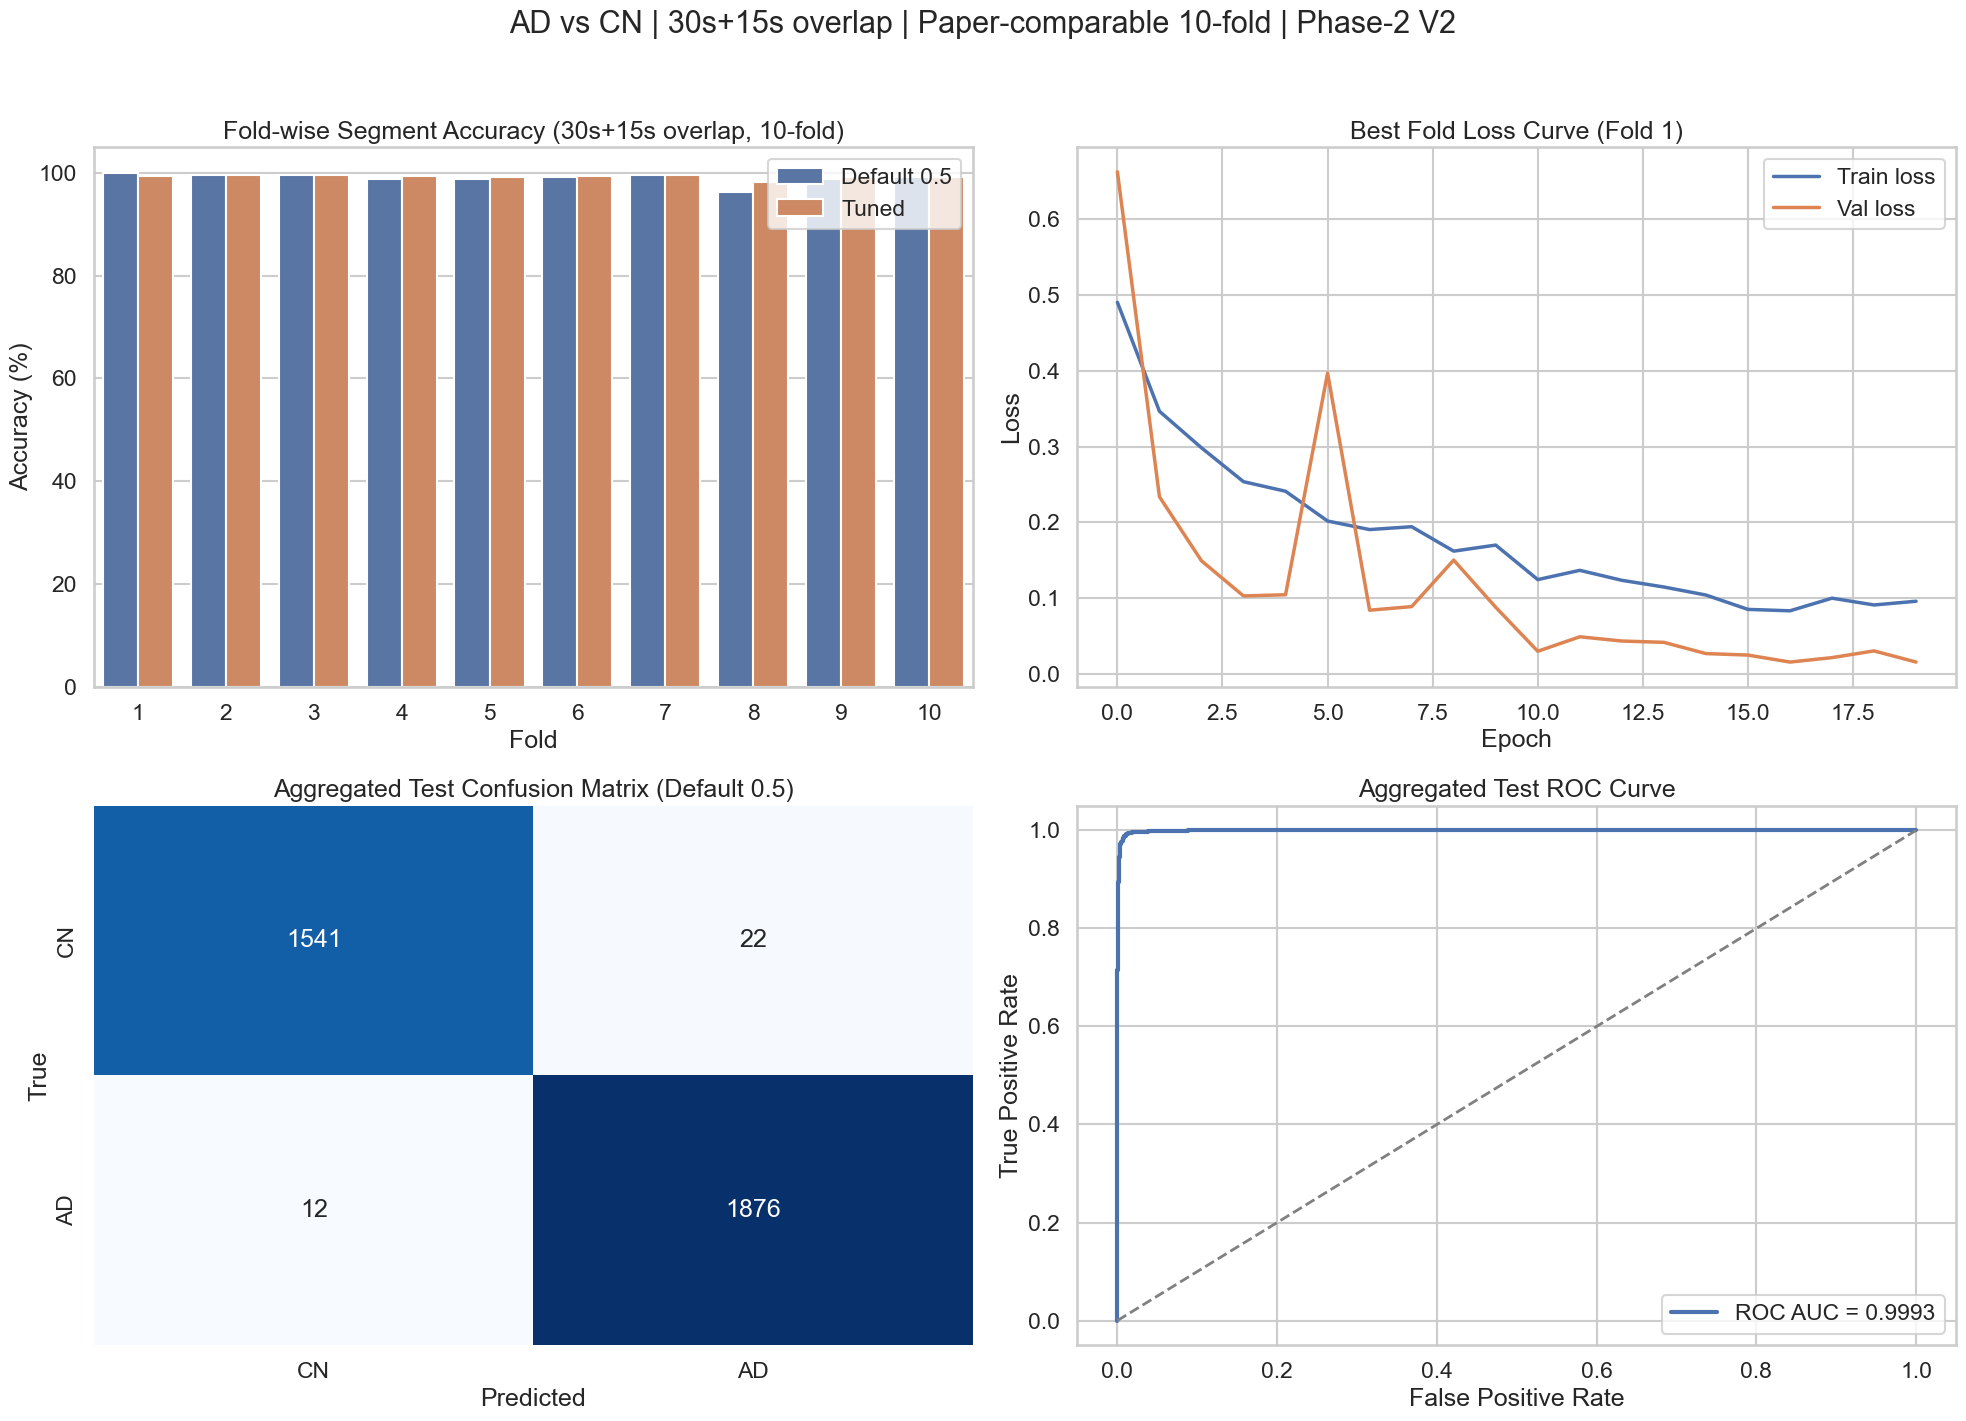

Saved figure: C:\Users\U\Desktop\Shoili\eeg_ad_hc_rebuild\phase2_clean_30s_15s_overlap_paper10fold_batch8\beautiful_summary_figure.png


In [12]:
sns.set_theme(style="whitegrid", context="talk")

fold_df = pd.read_csv(FOLD_METRICS_CSV)
pred_df = pd.read_csv(SEGMENT_PREDS_CSV)

# aggregated confusion matrix and ROC
y_true_all = pred_df["y_true"].to_numpy().astype(int)
prob_all    = pred_df["prob_disease"].to_numpy().astype(float)
pred_all    = pred_df["pred_default_0_5"].to_numpy().astype(int)

cm = confusion_matrix(y_true_all, pred_all, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

fpr, tpr, _ = roc_curve(y_true_all, prob_all)
auc_all = roc_auc_score(y_true_all, prob_all)

# best fold history
best_fold    = int(fold_df.loc[fold_df["default_accuracy"].idxmax(), "fold"])
history_path = RUN_DIR / f"fold_{best_fold:02d}_history.csv"
hist_df      = pd.read_csv(history_path)

# 2x2 summary figure
fig, axes = plt.subplots(2, 2, figsize=(20, 14))

# --- panel 1: fold accuracies ---
acc_long = pd.DataFrame({
    "fold": np.concatenate([fold_df["fold"].values, fold_df["fold"].values]),
    "accuracy": np.concatenate([fold_df["default_accuracy"].values, fold_df["tuned_accuracy"].values]),
    "mode": ["Default 0.5"] * len(fold_df) + ["Tuned"] * len(fold_df),
})

sns.barplot(
    data=acc_long,
    x="fold",
    y="accuracy",
    hue="mode",
    ax=axes[0, 0]
)
axes[0, 0].set_title("Fold-wise Segment Accuracy (30s+15s overlap, 10-fold)")
axes[0, 0].set_xlabel("Fold")
axes[0, 0].set_ylabel("Accuracy (%)")
axes[0, 0].legend()

# --- panel 2: best fold training history ---
axes[0, 1].plot(hist_df["epoch"], hist_df["loss"],     label="Train loss", linewidth=2.5)
axes[0, 1].plot(hist_df["epoch"], hist_df["val_loss"], label="Val loss",   linewidth=2.5)
axes[0, 1].set_title(f"Best Fold Loss Curve (Fold {best_fold})")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Loss")
axes[0, 1].legend()

# --- panel 3: confusion matrix ---
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["CN", "AD"],
    yticklabels=["CN", "AD"],
    ax=axes[1, 0]
)
axes[1, 0].set_title("Aggregated Test Confusion Matrix (Default 0.5)")
axes[1, 0].set_xlabel("Predicted")
axes[1, 0].set_ylabel("True")

# --- panel 4: ROC curve ---
axes[1, 1].plot(fpr, tpr, linewidth=3, label=f"ROC AUC = {auc_all:.4f}")
axes[1, 1].plot([0, 1], [0, 1], linestyle="--", linewidth=2, color="gray")
axes[1, 1].set_title("Aggregated Test ROC Curve")
axes[1, 1].set_xlabel("False Positive Rate")
axes[1, 1].set_ylabel("True Positive Rate")
axes[1, 1].legend(loc="lower right")

plt.suptitle("AD vs CN | 30s+15s overlap | Paper-comparable 10-fold | Phase-2 V2", fontsize=22, y=1.02)
plt.tight_layout()

fig_path = RUN_DIR / "beautiful_summary_figure.png"
plt.savefig(fig_path, dpi=220, bbox_inches="tight")
plt.show()

print("Saved figure:", fig_path)


In [13]:
summary_df = pd.read_csv(RUN_DIR / "summary.csv")

main_summary = summary_df[summary_df["metric"].isin([
    "default_accuracy",
    "default_sensitivity",
    "default_specificity",
    "default_precision",
    "default_f1",
    "default_roc_auc",
    "fold_time_min",
])].copy()

secondary_summary = summary_df[summary_df["metric"].isin([
    "tuned_accuracy",
    "tuned_sensitivity",
    "tuned_specificity",
    "tuned_precision",
    "tuned_f1",
    "tuned_roc_auc",
    "best_threshold",
])].copy()

print("MAIN SUMMARY")
display(main_summary)

print("SECONDARY SUMMARY")
display(secondary_summary)

print("Mean default accuracy:",
      float(main_summary.loc[main_summary["metric"] == "default_accuracy", "mean"].values[0]))


MAIN SUMMARY


,metric,mean,std,min,max
1,fold_time_min,32.869148,0.172991,32.598805,33.223089
2,default_accuracy,99.014493,1.068933,96.231884,100.000000
3,default_sensitivity,99.363954,0.699257,97.872340,100.000000
4,default_specificity,98.590968,2.336495,92.307692,100.000000
5,default_precision,98.874493,1.823837,94.000000,100.000000
6,default_f1,0.991089,0.009479,0.966581,1.000000
7,default_roc_auc,0.999634,0.000586,0.998033,1.000000


SECONDARY SUMMARY


,metric,mean,std,min,max
0,best_threshold,0.485500,0.314267,0.050000,0.950000
8,tuned_accuracy,99.304515,0.436440,98.260870,99.710145
9,tuned_sensitivity,99.469492,0.560097,98.404255,100.000000
10,tuned_specificity,99.103789,0.810558,97.435897,100.000000
11,tuned_precision,99.265069,0.662068,97.905759,100.000000
12,tuned_f1,0.993652,0.003969,0.984211,0.997361
13,tuned_roc_auc,0.999634,0.000586,0.998033,1.000000


Mean default accuracy: 99.0144927536232
